# Web scraping HKTV Mall Website On Beef Steaks

## Setup

In [43]:
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By # used for waiting page to load
from selenium.webdriver.support.ui import WebDriverWait # used for waiting page to load
from selenium.webdriver.support import expected_conditions as EC # used for waiting page to load
from bs4 import BeautifulSoup as bs
import re

url = "https://www.hktvmall.com/hktv/en/search_a?keyword=beef%20steak"
chrome_options = Options()
if "driver" in globals():
    try:
        driver.quit()
    except Exception:
        pass
driver = webdriver.Chrome(options=chrome_options)
driver.get(url)

## Set up variables

In [44]:
granditemlistName = []
granditemlistPrice = []
granditemlistSold = []

## Start scraping process
Note that sometimes an annoying login page may pop up. Either login to HKTV Mall if you have an account or try again after a restart.

In [45]:
import re
from bs4 import BeautifulSoup as bs

def read_page_count(page_source):
    soup = bs(page_source, "html.parser")
    for span in soup.find_all("span"):
        style = span.get("style") or ""
        if "font-weight:600" not in style.replace(" ", ""):
            continue
        match = re.search(r"(\d+)\s*Pages", span.get_text(" ", strip=True), flags=re.IGNORECASE)
        if match:
            return int(match.group(1))
    return None

def product_names(page_source):
    soup = bs(page_source, "html.parser")
    return [el.get_text(strip=True) for el in soup.find_all("div", class_="brand-product-name")]

def rows_from_page(page_source):
    # Stay inside the block that contains only this product, so its price and sales stay with its name.
    soup = bs(page_source, "html.parser")
    names = []
    prices = []
    solds = []
    for name_el in soup.find_all("div", class_="brand-product-name"):
        node = name_el
        while node.parent is not None and len(node.parent.find_all("div", class_="brand-product-name")) == 1:
            node = node.parent
        price_text = None
        sold_text = None
        for price_el in node.find_all("div", class_="price"):
            text = price_el.get_text(" ", strip=True)
            if re.search(r"\d", text):
                price_text = text
        sold_el = node.find("div", class_="salesNumber-container")
        if sold_el is not None:
            sold_text = sold_el.get_text(" ", strip=True)
        names.append(name_el.get_text(strip=True))
        prices.append(price_text)
        solds.append(sold_text)
    return names, prices, solds

driver.get(url)
granditemlistName = []
granditemlistPrice = []
granditemlistSold = []

WebDriverWait(driver, 20).until(
    EC.presence_of_element_located((By.CLASS_NAME, "brand-product-name"))
)
WebDriverWait(driver, 20).until(lambda d: read_page_count(d.page_source) is not None)
number = read_page_count(driver.page_source)
print(number, "pages")

warned_fallback = False
for i in range(number):
    WebDriverWait(driver, 20).until(
        EC.presence_of_element_located((By.CLASS_NAME, "brand-product-name"))
    )
    itemlistName, itemlistPrice, itemlistSold = rows_from_page(driver.page_source)
    if len(itemlistName) == 0:
        raise RuntimeError(f"Page {i + 1} had no product names. The product selector may have changed.")
    if all(price is None for price in itemlistPrice):
        if not warned_fallback:
            print("Prices were not inside the product cards; reading the page-level price and sales lists instead.")
            warned_fallback = True
        soup = bs(driver.page_source, "html.parser")
        itemlistPrice = [el.get_text(" ", strip=True) for el in soup.find_all("div", class_="price")]
        itemlistSold = [el.get_text(" ", strip=True) for el in soup.find_all("div", class_="salesNumber-container")]
        if not (len(itemlistName) == len(itemlistPrice) == len(itemlistSold)):
            raise ValueError(
                "Could not pair names with prices and sales "
                f"({len(itemlistName)} names, {len(itemlistPrice)} prices, {len(itemlistSold)} sales)."
            )
    granditemlistName += itemlistName
    granditemlistPrice += itemlistPrice
    granditemlistSold += itemlistSold
    print(f"page {i + 1}: {len(itemlistName)} products")
    if i < number - 1:
        previous_names = tuple(itemlistName)
        button = WebDriverWait(driver, 20).until(
            EC.presence_of_element_located((By.ID, "sortMenu_next"))
        )
        driver.execute_script("arguments[0].scrollIntoView({block: 'center'});", button)
        driver.execute_script("arguments[0].click();", button)
        # The next page can still show the old product names for a moment.
        WebDriverWait(driver, 20).until(
            lambda d, previous=previous_names: tuple(product_names(d.page_source)) not in ((), previous)
        )

print(len(granditemlistName), "products")

9 pages
page 1: 60 products
page 2: 60 products
page 3: 60 products
page 4: 60 products
page 5: 60 products
page 6: 60 products
page 7: 60 products
page 8: 60 products
page 9: 48 products
528 products


## Store variables

In [46]:
newitemlistPrice = list(granditemlistPrice)
newitemlistName = list(granditemlistName)
newitemlistSold = list(granditemlistSold)

## Edit Variables

In [47]:
import re

def clean_price(text):
    if text is None:
        return None
    matches = re.findall(r"\d[\d,]*(?:\.\d+)?", str(text))
    if not matches:
        return None
    return matches[-1].replace(",", "")

def clean_sales(text):
    if text is None:
        return ""
    raw = str(text).strip()
    if raw == "":
        return "0"
    head = raw.split("+", 1)[0].replace(",", "").replace(" ", "")
    if re.fullmatch(r"\d+(?:\.\d+)?", head):
        return head
    return ""

newitemlistPrice = [clean_price(text) for text in granditemlistPrice]
neweritemlistSold = [clean_sales(text) for text in granditemlistSold]

## Create table

In [48]:
import pandas as pd

name_count = len(granditemlistName)
price_count = len(newitemlistPrice)
sales_count = len(neweritemlistSold)
if not (name_count == price_count == sales_count):
    raise ValueError(
        "The name, price, and sales lists are different lengths "
        f"({name_count} names, {price_count} prices, {sales_count} sales). "
        "Run the scrape and edit cells again."
    )

df = pd.DataFrame({
    "Product Name": granditemlistName,
    "Price": newitemlistPrice,
    "Number of sales": neweritemlistSold,
})
df["Number of sales"] = df["Number of sales"].apply(lambda x: str(x).replace(",", "").replace(" ", ""))
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Number of sales"] = pd.to_numeric(df["Number of sales"], errors="coerce")

## Add Classes 

In [49]:
df["Steak Category"] = "Other"
df["Product Type"] = "Steak"
df["Wagyu?"] = "False"
name = df["Product Name"]
# Country names and the English adjectives used on labels. The UK is separate.
europe_terms = [
    "Albania", "Albanian",
    "Andorra", "Andorran",
    "Armenia", "Armenian",
    "Austria", "Austrian",
    "Azerbaijan", "Azerbaijani", "Azeri",
    "Belarus", "Belarusian",
    "Belgium", "Belgian",
    "Bosnia and Herzegovina", "Bosnia & Herzegovina", "Bosnia-Herzegovina", "Bosnia–Herzegovina",
    "Bosnia", "Bosnian", "Herzegovina",
    "Bulgaria", "Bulgarian",
    "Croatia", "Croatian",
    "Cyprus", "Cypriot",
    "Czech Republic", "Czechia", "Czech",
    "Denmark", "Danish",
    "Estonia", "Estonian",
    "Finland", "Finnish",
    "France", "French",
    "Georgia", "Georgian",
    "Germany", "German",
    "Greece", "Greek",
    "Hungary", "Hungarian",
    "Iceland", "Icelandic",
    "Ireland", "Irish",
    "Italy", "Italian",
    "Kazakhstan", "Kazakhstani", "Kazakh",
    "Kosovo", "Kosovar", "Kosovan",
    "Latvia", "Latvian",
    "Liechtenstein", "Liechtensteiner",
    "Lithuania", "Lithuanian",
    "Luxembourg", "Luxembourgish", "Luxembourger",
    "Malta", "Maltese",
    "Moldova", "Moldovan", "Moldavian", "Moldavia",
    "Monaco", "Monegasque",
    "Montenegro", "Montenegrin",
    "Netherlands", "Holland", "Dutch",
    "North Macedonia", "Macedonia", "Macedonian",
    "Norway", "Norwegian",
    "Poland", "Polish",
    "Portugal", "Portuguese",
    "Romania", "Romanian",
    "Russian Federation", "Russia", "Russian",
    "San Marino", "Sammarinese",
    "Serbia", "Serbian",
    "Slovakia", "Slovak",
    "Slovenia", "Slovenian", "Slovene",
    "Spain", "Spanish",
    "Sweden", "Swedish",
    "Switzerland", "Swiss",
    "Turkey", "Türkiye", "Turkish",
    "Ukraine", "Ukrainian",
    "Vatican City", "Holy See", "Vatican",
    "Europe", "European",
]
# Northern Ireland stays UK. Poultry titles such as "turkey breast" stay out of Europe.
guards = {
    "Ireland": r"(?<!\bN )(?<!\bN\. )(?<!Northern)(?<!Northern\s)Ireland",
    "Turkey": (
        r"(?<!sliced )(?<!smoked )(?<!roast )(?<!roasted )(?<!ground )"
        r"(?<!minced )(?<!fried )(?<!grilled )(?<!whole )"
        r"Turkey(?!\s+(?:breast|breasts|meat|leg|legs|wing|wings|mince|minced|"
        r"sausage|sausages|bacon|ham|slice|slices|fillet|fillets|thigh|thighs|"
        r"drumstick|drumsticks|burger|burgers|meatball|meatballs|steak|steaks)\b)"
    ),
}
parts = [guards.get(term, term) for term in sorted(europe_terms, key=len, reverse=True)]
europe_pattern = r"\b(?:" + "|".join(parts) + r")\b"
# Europe is first so a more specific origin replaces it when a title matches both.
df.loc[name.str.contains(europe_pattern, case=False, na=False, regex=True), "Steak Category"] = "Europe"
df.loc[name.str.contains(r"Australia|\bAUS\b", case=False, na=False, regex=True), "Steak Category"] = "Australian"
df.loc[name.str.contains(r"United States|\bAmerica|\bUSA\b|U\.S\.A|\bUS|\bU.S.", case=False, na=False, regex=True), "Steak Category"] = "American"
df.loc[name.str.contains(r"New\s*Zealand|\bNZ\b", case=False, na=False, regex=True), "Steak Category"] = "New Zealand"
df.loc[name.str.contains(r"Japan|\bJP\b|Nippon\b", case=False, na=False, regex=True), "Steak Category"] = "Japanese"
uk_pattern = (
    r"United\s+Kingdom|\bU\.K\.?|\bUK\b|Great\s+Britain|\bBritain\b|\bBritish\b|"
    r"\b(?<!New)(?<!New\s)England\b|\bEnglish\b|\bScotland\b|\bScottish\b|"
    r"\bWales\b|\bWelsh\b|Northern\s*Ireland|\bN\.?\s*Ireland\b|\bGB\b"
)
df.loc[name.str.contains(uk_pattern, case=False, na=False, regex=True), "Steak Category"] = "UK"
df.loc[name.str.contains(r"\b(?:Brazil|Brazilian|Brasil)\b", case=False, na=False, regex=True), "Steak Category"] = "Brazil"
df.loc[name.str.contains(r"\b(?:Argentina|Argentinian|Argentine)\b", case=False, na=False, regex=True), "Steak Category"] = "Argentina"
df.loc[name.str.contains(r"\bBars?\b", case=False, na=False, regex=True), "Product Type"] = "Bar"
df.loc[name.str.contains(r"\bDogs?\b", case=False, na=False, regex=True), "Product Type"] = "Dog Food"
df.loc[name.str.contains(r"\bJerky\b", case=False, na=False, regex=True), "Product Type"] = "Jerky"
df.loc[name.str.contains(r"\bSticks?\b", case=False, na=False, regex=True), "Product Type"] = "Stick"
df.loc[name.str.contains(r"\bSauces?\b", case=False, na=False, regex=True), "Product Type"] = "Sauce"
df.loc[name.str.contains(r"Wagyu", case=False, na=False, regex=True), "Wagyu?"] = "True"


### Section to display Table

In [50]:
df

,Product Name,Price,Number of sales,Steak Category,Product Type,Wagyu?
0,THE MARKET - US Prime Beef Top Blade Steak 330...,149.0,10000,American,Steak,False
1,THE MARKET - U.S. Angus Beef Short Rib Boneles...,169.9,30000,American,Steak,False
2,THE MARKET - US Augus Beef Rib Eye Steak (Frozen),92.0,90000,American,Steak,False
3,Sun Hing Man Kee Beef - Sliced Chuck Steak (0....,138.0,3000,Other,Steak,False
4,Australia YP Grass-Fed Black Angus Beef T-Bone...,129.0,500,Australian,Steak,False
...,...,...,...,...,...,...
523,Mitsuboshi Farm - ◆ Japanese-style Frozen Bent...,59.9,80,Japanese,Steak,False
524,Mitsuboshi Farm - ◆ Healthy Japanese Bento ◆ B...,59.9,20,Japanese,Sauce,False
525,LH Vegan - Vegan Black Pepper Steak -4 Slices ...,38.0,100,Other,Steak,False
526,Wrights - Wrights Steak & Ale Premium Pie 215g...,78.0,30,Other,Steak,False


### Section to save table 

In [51]:
#IMPORTANT: MAKE SURE YOUR TABLE INPUT NAME IS UNIQUE, OTHERWISE THIS WILL CRASH!
datatableName = input("Table name").strip()
if datatableName.lower().endswith(".xlsx"):
    datatableName = datatableName[:-5].strip()
if datatableName == "":
    raise ValueError("Enter a file name without .xlsx")
df.to_excel(f"{datatableName}.xlsx", index=False)

Table name table222


### Conclusion: which location produces the best steaks

In [52]:
tableofsteaks = df[df["Product Type"] == "Steak"]
groups = tableofsteaks.groupby("Steak Category")[["Number of sales", "Price"]].mean()

In [53]:
groups

,Number of sales,Price
Steak Category,,
American,5364.259259,177.010185
Argentina,1222.173913,281.385714
Australian,327.727273,192.060606
Brazil,860.000000,82.920000
Europe,1011.250000,162.200000
Japanese,516.000000,195.080000
New Zealand,7581.818182,154.040909
Other,344.514286,222.577600
UK,455.000000,82.000000


### Conclusion: which location produces the most Wagyu steaks 

In [54]:
wagyu_steaks = df[(df["Product Type"] == "Steak") & (df["Wagyu?"] == "True")]
counts = (
    wagyu_steaks.groupby("Steak Category")
    .size()
    .reindex(["Australian", "American", "Japanese", "New Zealand", "Europe", "UK", "Brazil", "Argentina", "Other"], fill_value=0)
    .sort_values(ascending=False)
)
counts

Steak Category
Other          48
Japanese       34
Australian     15
American        3
New Zealand     1
UK              1
Europe          0
Brazil          0
Argentina       0
dtype: int64

In [56]:
df[df["Steak Category"] == "New Zealand"]

,Product Name,Price,Number of sales,Steak Category,Product Type,Wagyu?
10,Foodianna - [Beef] · NZ Angus Beef Burger stea...,29.9,900,New Zealand,Steak,False
12,大滋野 - [Beef] · New Zealand Angus Jumbo Beef Bu...,39.9,0,New Zealand,Steak,False
13,大滋野 - [Beef] · New Zealand Angus Jumbo Beef Bu...,39.9,500,New Zealand,Steak,False
14,Foodianna - [Beef] · NZ Angus Beef Burger stea...,29.9,0,New Zealand,Steak,False
16,Foodianna - [Beef] · NZ Angus Beef Burger stea...,54.9,800,New Zealand,Steak,False
17,Foodianna - [Beef] · NZ Angus Beef Burger stea...,56.8,0,New Zealand,Steak,False
54,MyFridge - New Zealand Grass-Fed Beef Striploi...,79.8,40,New Zealand,Steak,False
58,MyFridge - New Zealand Grass-Fed Beef Striploi...,79.8,30,New Zealand,Steak,False
98,HELLABY - NZ Hellaby's 100% Grass-Fed Beef OP ...,399.0,0,New Zealand,Steak,False
147,ERIK’S MEATS - FROZEN NEW ZEALAND GRASS-FED SI...,76.0,30000,New Zealand,Steak,False


## Charts

Pie charts show how the listings split by origin and by product type. The bar charts use the steak averages and the Wagyu counts from the cells above.

HKTV prints sales as a floor, so one listing at `5000+` can make a sales bar much taller than the others.

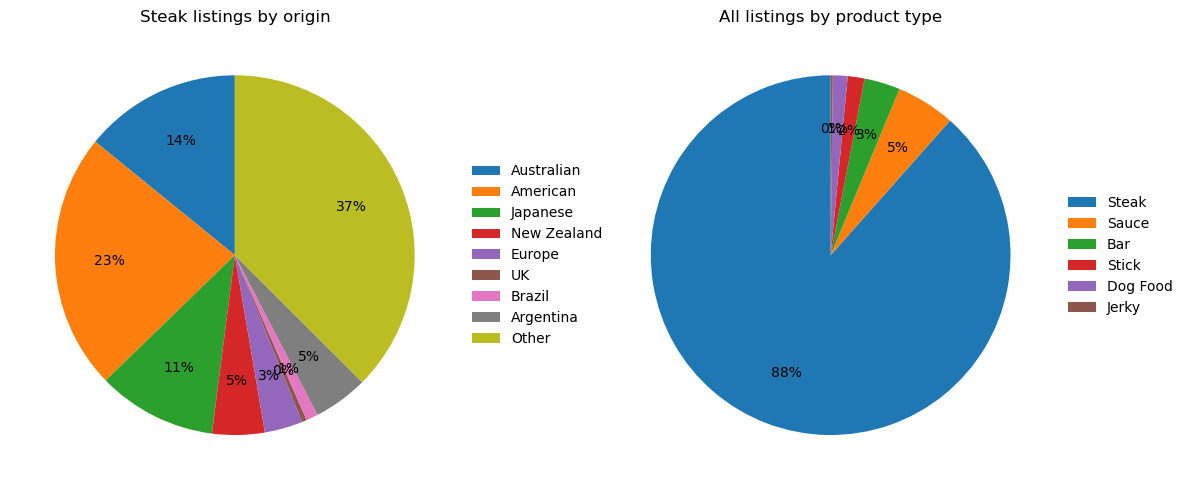

In [58]:
import matplotlib.pyplot as plt

def draw_pie(ax, counts, title):
    counts = counts[counts > 0]
    if counts.empty:
        ax.text(0.5, 0.5, "No rows", ha="center", va="center")
        ax.set_axis_off()
        ax.set_title(title)
        return
    wedges, _, _ = ax.pie(counts, autopct="%1.0f%%", startangle=90, pctdistance=0.7)
    ax.legend(wedges, counts.index, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
    ax.set_title(title)

origin_order = ["Australian", "American", "Japanese", "New Zealand", "Europe", "UK", "Brazil", "Argentina", "Other"]
steaks = df[df["Product Type"] == "Steak"]
origin_counts = steaks["Steak Category"].value_counts().reindex(origin_order, fill_value=0)
type_counts = df["Product Type"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
draw_pie(axes[0], origin_counts, "Steak listings by origin")
draw_pie(axes[1], type_counts, "All listings by product type")
fig.tight_layout()
plt.show()

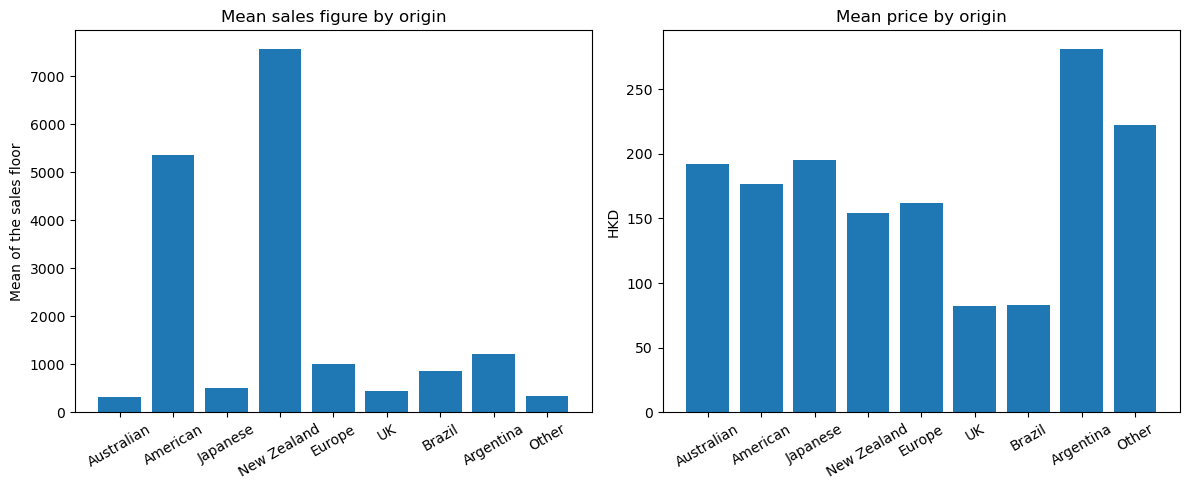

In [59]:
import matplotlib.pyplot as plt

def draw_bar(ax, series, title, ylabel):
    if series.empty:
        ax.text(0.5, 0.5, "No rows", ha="center", va="center")
        ax.set_axis_off()
        ax.set_title(title)
        return
    ax.bar(series.index.astype(str), series)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=30)

origin_order = ["Australian", "American", "Japanese", "New Zealand", "Europe", "UK", "Brazil", "Argentina", "Other"]
plot_groups = groups.reindex(origin_order)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
draw_bar(axes[0], plot_groups["Number of sales"].dropna(), "Mean sales figure by origin", "Mean of the sales floor")
draw_bar(axes[1], plot_groups["Price"].dropna(), "Mean price by origin", "HKD")
fig.tight_layout()
plt.show()

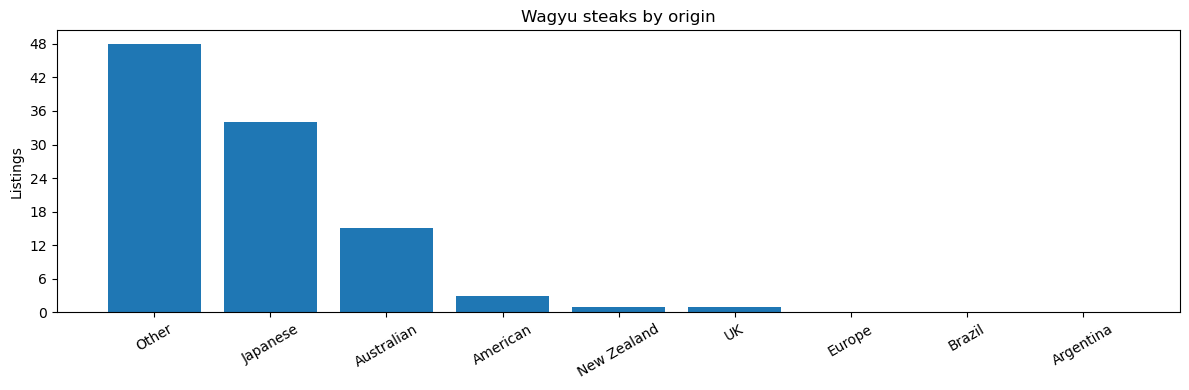

In [60]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(counts.index.astype(str), counts)
ax.set_title("Wagyu steaks by origin")
ax.set_ylabel("Listings")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

## Top 10 suggestions

The table ranks steak listings a shopper might buy. A listing is scored only when it passes every check below.

- Product type is Steak, the price is above 0, and the sales floor is above 0.
- The name includes a steak cut, such as steak, ribeye, sirloin, striploin, tenderloin, or hanging tender.
- Cat food, dog food, pork, chicken, lamb, mushrooms, vegan products, patties, and tools are left out.

Each listing that passes gets three scores from 0 to 1.

- Popularity, weight 0.50, is the log of the sales floor. A `100000+` floor stays on the same scale as the smaller floors.
- Affordability, weight 0.30, is higher when the price is lower.
- Wagyu points, weight 0.20, is 1 when the name says Wagyu, and 0 otherwise.

Score = 0.50 x Popularity + 0.30 x Affordability + 0.20 x Wagyu points.

Steak Category is shown beside each suggestion. The score uses popularity, affordability, and Wagyu only, so a listing from any origin can rank. Repeated names keep the row with the higher score. The table is the 10 highest scores, ranked from the scraped price, sales floor, and Wagyu label.


In [61]:
import math

POPULARITY_WEIGHT = 0.50
AFFORDABILITY_WEIGHT = 0.30
WAGYU_WEIGHT = 0.20

candidates = df[df["Product Type"] == "Steak"].copy()
name = candidates["Product Name"]
is_cut = name.str.contains(
    r"steak|rib\s*eye|ribeye|striploin|strip\s*loin|sirloin|tenderloin|"
    r"fillet|filet|t-?bone|tomahawk|flat\s*iron|picanha|flank|skirt|hanging\s*tender",
    case=False,
    na=False,
    regex=True,
)
is_other_food = name.str.contains(
    r"\bcats?\b|\bdogs?\b|\bpork\b|\bchicken\b|\blamb\b|\bmushrooms?\b|"
    r"\bvegan\b|\bclips?\b|\bhamburgers?\b|\bpatties\b|\bpatty\b",
    case=False,
    na=False,
    regex=True,
)
candidates = candidates[
    is_cut
    & ~is_other_food
    & candidates["Price"].notna()
    & (candidates["Price"] > 0)
    & candidates["Number of sales"].notna()
    & (candidates["Number of sales"] > 0)
].copy()

def unit_interval(series, higher_is_better):
    low = series.min()
    high = series.max()
    if series.empty or pd.isna(low) or high == low:
        scaled = pd.Series(1.0, index=series.index)
    else:
        scaled = (series - low) / (high - low)
    if not higher_is_better:
        scaled = 1 - scaled
    return scaled

columns = [
    "Rank",
    "Product Name",
    "Steak Category",
    "Price",
    "Number of sales",
    "Wagyu?",
    "Popularity",
    "Affordability",
    "Wagyu points",
    "Score",
]
score_columns = ["Popularity", "Affordability", "Wagyu points", "Score"]
if candidates.empty:
    top10 = pd.DataFrame(columns=columns).set_index("Rank")
else:
    candidates["Popularity"] = unit_interval(candidates["Number of sales"].map(math.log1p), True)
    candidates["Affordability"] = unit_interval(candidates["Price"], False)
    candidates["Wagyu points"] = (candidates["Wagyu?"] == "True").astype(float)
    candidates["Score"] = (
        POPULARITY_WEIGHT * candidates["Popularity"]
        + AFFORDABILITY_WEIGHT * candidates["Affordability"]
        + WAGYU_WEIGHT * candidates["Wagyu points"]
    )
    ranked = candidates.sort_values(["Score", "Number of sales"], ascending=False)
    ranked = ranked.drop_duplicates("Product Name")
    top10 = ranked.head(10).copy()
    top10.insert(0, "Rank", range(1, len(top10) + 1))
    top10 = top10.loc[:, columns].copy()
    top10.loc[:, score_columns] = top10.loc[:, score_columns].round(3)
    top10.loc[:, "Number of sales"] = top10["Number of sales"].round().astype(int)
    top10 = top10.set_index("Rank")
top10


,Product Name,Steak Category,Price,Number of sales,Wagyu?,Popularity,Affordability,Wagyu points,Score
Rank,,,,,,,,,
1,THE MARKET - US Augus Beef Rib Eye Steak (Frozen),American,92.0,90000,False,0.988,0.928,0.0,0.773
2,The Meat Guy - \USDA Prime Grade Beef Flat Iro...,American,92.0,90000,False,0.988,0.928,0.0,0.773
3,Ashley - Selected New Zealand Striploin (2 pcs...,New Zealand,130.0,100000,False,1.000,0.887,0.0,0.766
4,Nikuya - A5 Wagyu Kurashita steak (Frozen),Other,179.0,3000,True,0.615,0.834,1.0,0.758
5,THE MARKET - US Prime Beef Top Blade Steak 330...,American,49.9,40000,False,0.899,0.973,0.0,0.742
6,THE MARKET - US Ribeye Steak (Frozen),American,72.9,40000,False,0.899,0.948,0.0,0.734
7,ERIK’S MEATS - FROZEN NEW ZEALAND GRASS-FED SI...,New Zealand,76.0,30000,False,0.868,0.945,0.0,0.717
8,RAKU MI DOU - A5 Japanese Wagyu [Striploin Ste...,Japanese,142.0,1000,True,0.495,0.874,1.0,0.710
9,THE MARKET - US Angus Chuck Eye Roll Steak 400g,American,108.0,30000,False,0.868,0.911,0.0,0.707


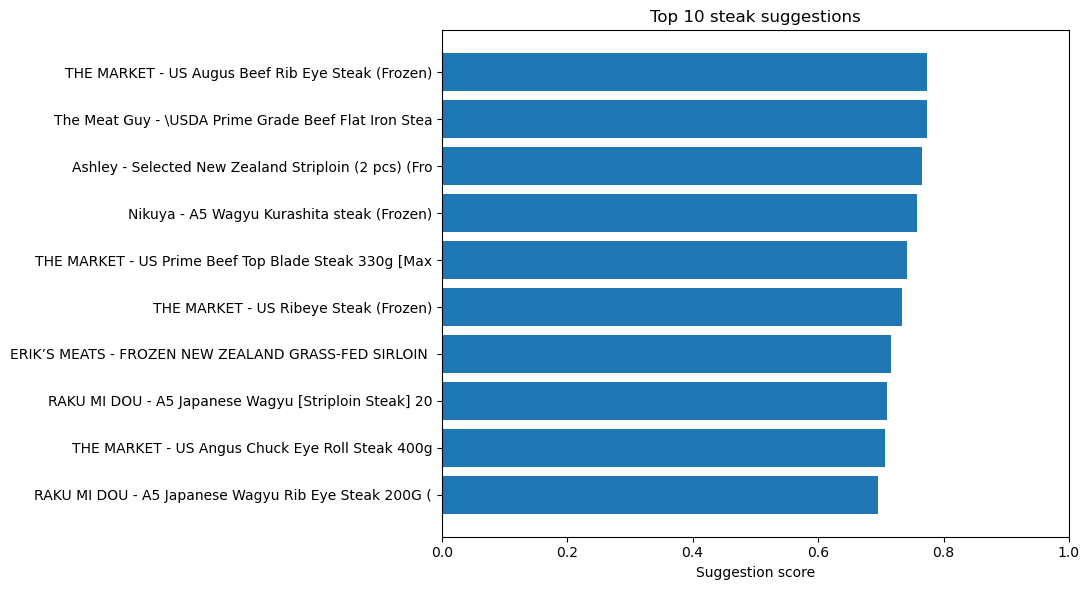

In [62]:
import matplotlib.pyplot as plt

if top10.empty:
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.text(0.5, 0.5, "No rows", ha="center", va="center")
    ax.set_axis_off()
else:
    labels = top10["Product Name"].str.replace(r"\s+", " ", regex=True).str.slice(0, 52)
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.barh(labels.iloc[::-1], top10["Score"].iloc[::-1])
    ax.set_xlabel("Suggestion score")
    ax.set_xlim(0, 1)
ax.set_title("Top 10 steak suggestions")
fig.tight_layout()
plt.show()
